Raw shape: (479, 33)
Missing values:
 race_time_or_gap         60
gap_to_winner_seconds    55
fastest_lap_rank         22
fastest_lap              22
fastest_lap_number       22
dtype: int64
Duplicates: 0

Points -> mean, min, max, sum, std, median: 5.061 0.0 25.0 2424.0 7.176 1.0

Correlation matrix:
                        grid_position  finish_position  laps_completed  \
grid_position                   1.00             0.69           -0.07   
finish_position                 0.69             1.00           -0.31   
laps_completed                 -0.07            -0.31            1.00   
gap_to_winner_seconds           0.29             0.16            0.06   
points                         -0.72            -0.86            0.15   
grid_places_gained              0.44            -0.35            0.29   
fastest_lap_seconds             0.05             0.07           -0.59   

                       gap_to_winner_seconds  points  grid_places_gained  \
grid_position                      

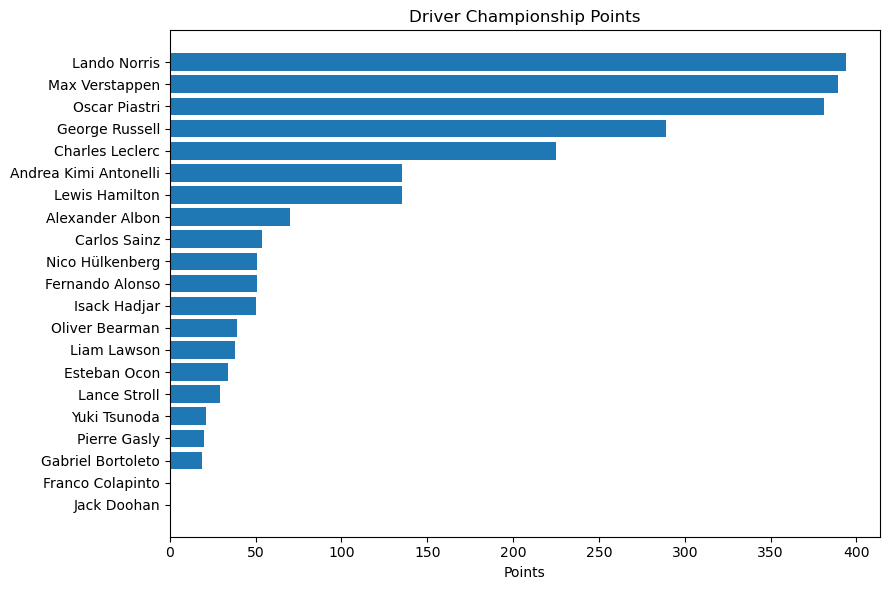

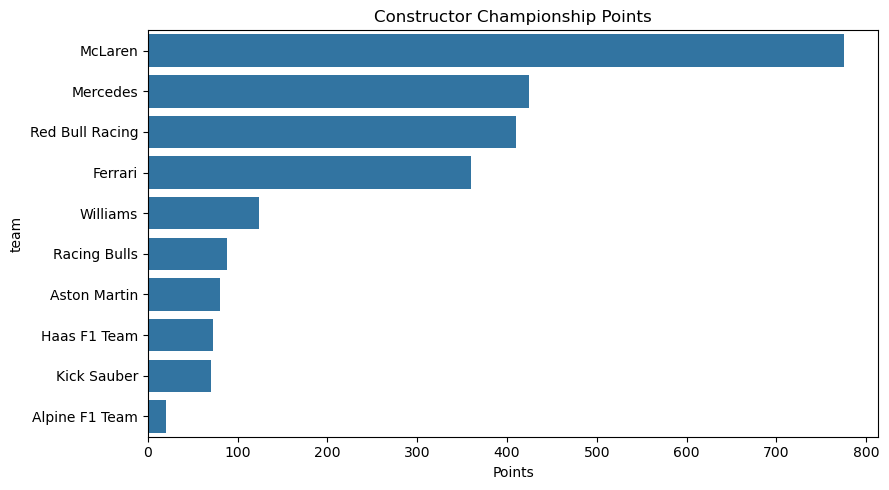

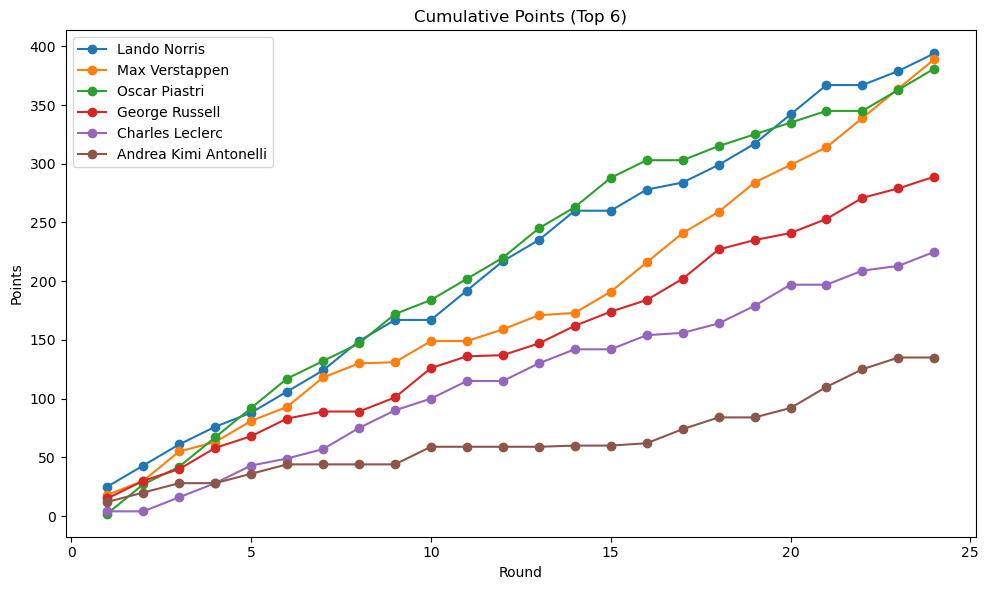

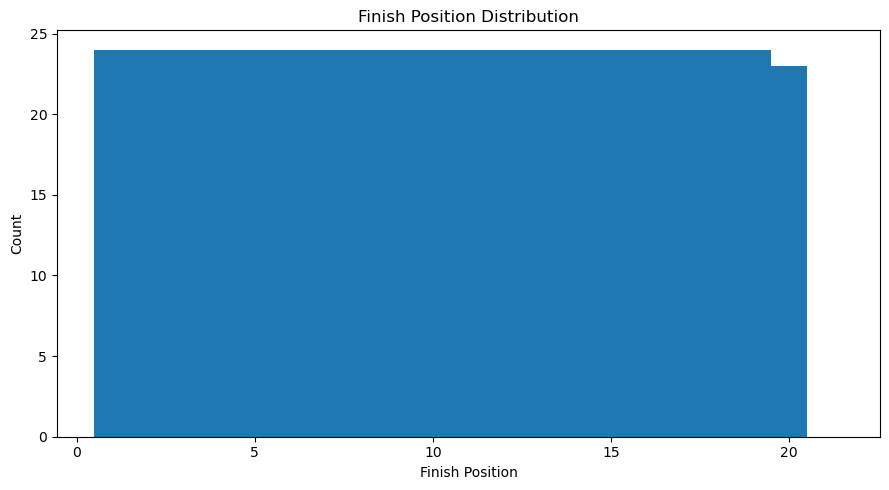

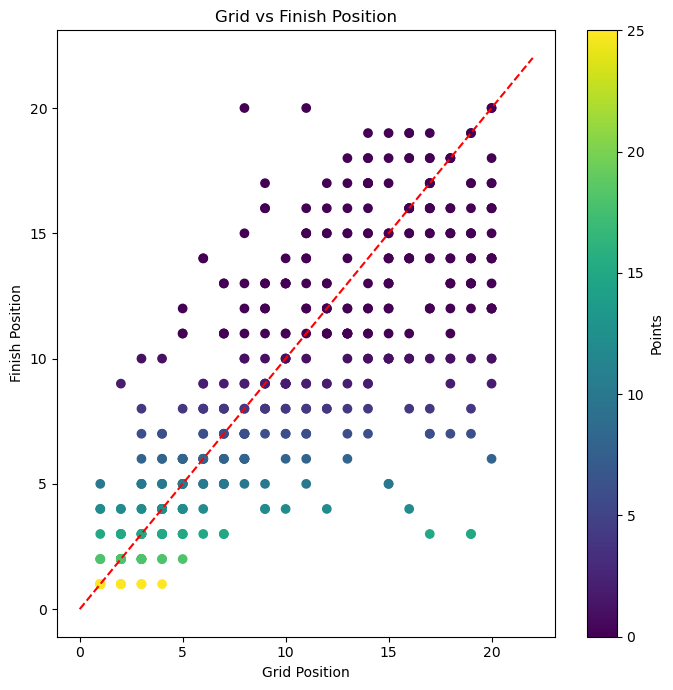

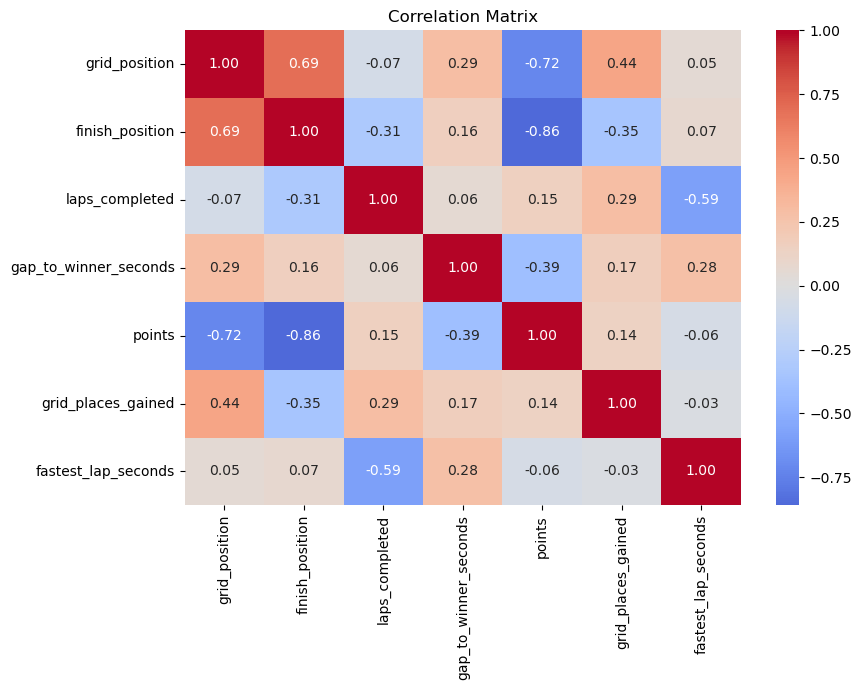

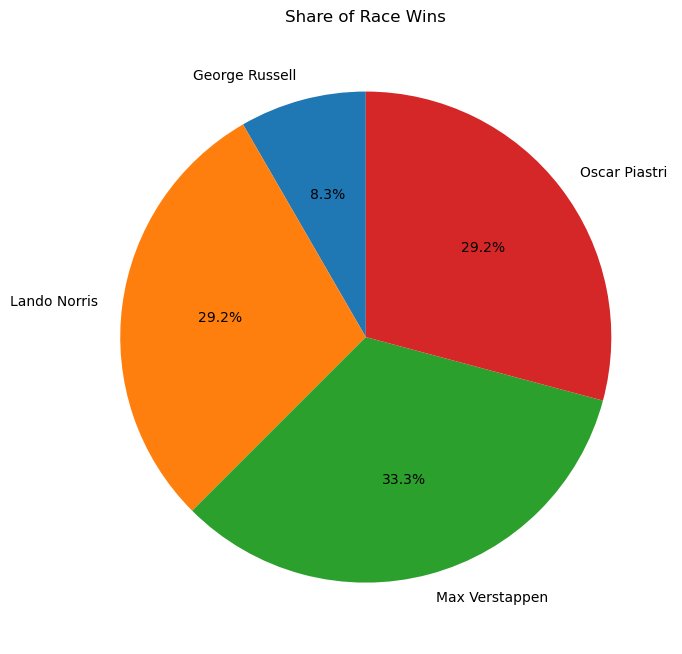

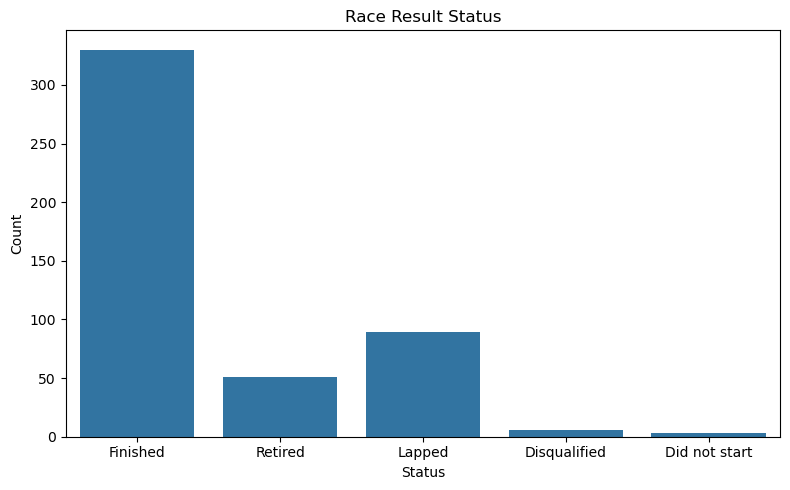

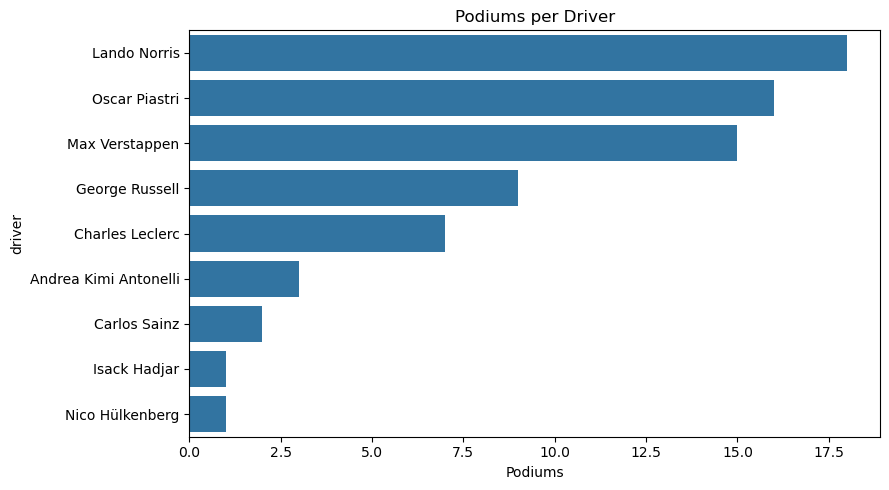

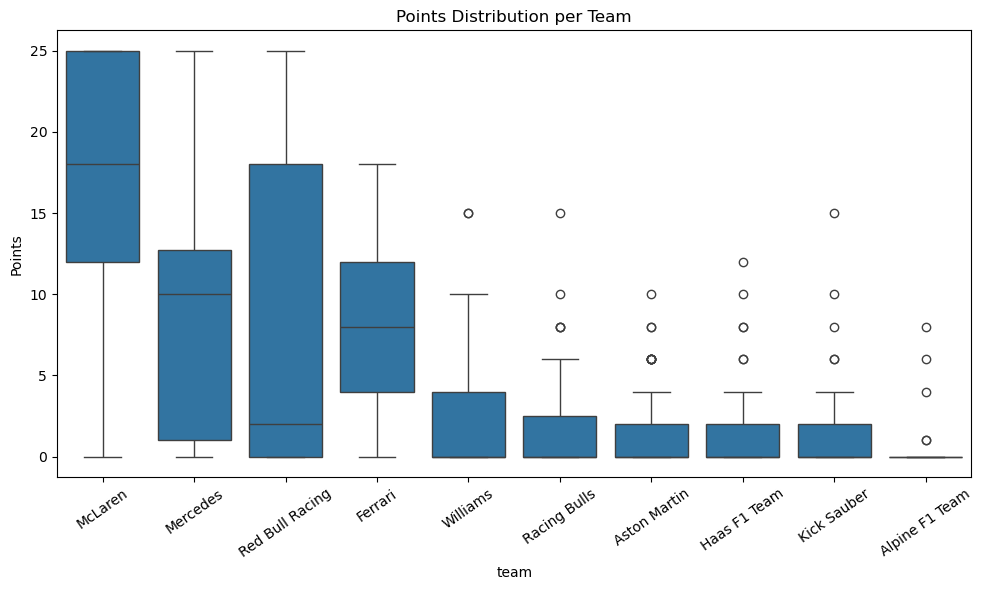


Done. 10 charts displayed and saved in charts/, cleaned data in f1_2025_cleaned.csv


In [6]:
# =============================================================================
# F1 2025 GRAND PRIX RESULTS — MINIMAL ALL-IN-ONE ANALYSIS
# Team: Soham Hande & Anshu Navghare
# (a) Cleaning with Pandas | (b) Analysis with NumPy
# (c) Visualization with Matplotlib / Seaborn
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# In Jupyter / Google Colab uncomment the line below so charts appear inline:
# %matplotlib inline

# ---------------------------- (a) CLEANING WITH PANDAS ----------------------
df = pd.read_csv("C:/Users/Soham/Downloads/f1_2025_grand_prix_results.csv")
print("Raw shape:", df.shape)
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicates:", df.duplicated().sum())

df["race_date"] = pd.to_datetime(df["race_date"])                 # text -> date
df["country"] = df["country"].replace({"UK": "United Kingdom"})   # fix label
df["gap_to_winner_seconds"] = df["gap_to_winner_seconds"].fillna(0.0)
df.loc[df["gap_to_winner_seconds"] < 0, "gap_to_winner_seconds"] = 0.0
df["race_time_or_gap"] = df["race_time_or_gap"].fillna("Not Classified")
df["fastest_lap_rank"] = df["fastest_lap_rank"].fillna(0).astype(int)
df["fastest_lap"] = df["fastest_lap"].fillna("No Timed Lap")

def lap_to_seconds(x):                      # '1:22.167' -> 82.167
    if pd.isna(x) or x == "No Timed Lap":
        return np.nan
    m, rest = x.split(":")
    s, ms = rest.split(".")
    return int(m) * 60 + int(s) + int(ms) / 1000

df["fastest_lap_seconds"] = df["fastest_lap"].apply(lap_to_seconds)

clean = df[["round", "grand_prix", "race_date", "country", "circuit",
            "sprint_weekend", "driver", "team", "grid_position",
            "finish_position", "result_status", "classified", "laps_completed",
            "gap_to_winner_seconds", "points", "fastest_lap_rank",
            "fastest_lap_seconds", "grid_places_gained", "winner",
            "podium", "points_finish"]].copy()
clean.to_csv("f1_2025_cleaned.csv", index=False)

# ---------------------------- (b) ANALYSIS WITH NUMPY -----------------------
pts = clean["points"].to_numpy(float)
print("\nPoints -> mean, min, max, sum, std, median:",
      round(np.mean(pts), 3), np.min(pts), np.max(pts),
      np.sum(pts), round(np.std(pts), 3), np.median(pts))

num_cols = ["grid_position", "finish_position", "laps_completed",
            "gap_to_winner_seconds", "points", "grid_places_gained",
            "fastest_lap_seconds"]
corr = np.corrcoef(clean[num_cols].dropna().to_numpy(float), rowvar=False)
corr_df = pd.DataFrame(corr, index=num_cols, columns=num_cols).round(2)

driver_pts = clean.groupby("driver")["points"].sum().sort_values(ascending=False)
team_pts = clean.groupby("team")["points"].sum().sort_values(ascending=False)
wins = clean[clean.winner].groupby("driver").size()
podiums = clean[clean.podium].groupby("driver").size()

print("\nCorrelation matrix:\n", corr_df)
print("\nDriver standings:\n", driver_pts)
print("\nConstructor standings:\n", team_pts)
print("\nRace wins:\n", wins)
print("\nResult status:\n", clean["result_status"].value_counts())

# ---------------------------- (c) VISUALIZATION -----------------------------
os.makedirs("charts", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}", dpi=120)   # save as PNG file
    plt.show()                               # display the chart on screen

# 1. Driver points — horizontal bar (Matplotlib)
plt.figure(figsize=(9, 6))
plt.barh(driver_pts.sort_values().index, driver_pts.sort_values())
plt.title("Driver Championship Points"); plt.xlabel("Points")
save("01_driver_standings.png")

# 2. Team points — bar (Seaborn)
plt.figure(figsize=(9, 5))
sns.barplot(x=team_pts.values, y=team_pts.index)
plt.title("Constructor Championship Points"); plt.xlabel("Points")
save("02_team_standings.png")

# 3. Cumulative points — line (Matplotlib + NumPy cumsum)
plt.figure(figsize=(10, 6))
for drv in driver_pts.head(6).index:
    sub = clean[clean.driver == drv].sort_values("round")
    plt.plot(sub["round"], np.cumsum(sub.points.to_numpy()), marker="o", label=drv)
plt.title("Cumulative Points (Top 6)"); plt.xlabel("Round")
plt.ylabel("Points"); plt.legend()
save("03_points_progression.png")

# 4. Finish positions — histogram (Matplotlib)
plt.figure(figsize=(9, 5))
plt.hist(clean["finish_position"], bins=np.arange(0.5, 22.5, 1))
plt.title("Finish Position Distribution"); plt.xlabel("Finish Position")
plt.ylabel("Count")
save("04_finish_position_histogram.png")

# 5. Grid vs finish — scatter (Matplotlib)
cl = clean[clean.classified]
plt.figure(figsize=(7, 7))
plt.scatter(cl["grid_position"], cl["finish_position"], c=cl["points"])
plt.plot([0, 22], [0, 22], "r--")
plt.title("Grid vs Finish Position"); plt.xlabel("Grid Position")
plt.ylabel("Finish Position"); plt.colorbar(label="Points")
save("05_grid_vs_finish_scatter.png")

# 6. Correlation — heatmap (Seaborn)
plt.figure(figsize=(9, 7))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix")
save("06_correlation_heatmap.png")

# 7. Wins share — pie (Matplotlib)
plt.figure(figsize=(7, 7))
plt.pie(wins.values, labels=wins.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Race Wins")
save("07_wins_pie.png")

# 8. Result status — count plot (Seaborn)
plt.figure(figsize=(8, 5))
sns.countplot(x="result_status", data=clean)
plt.title("Race Result Status"); plt.xlabel("Status"); plt.ylabel("Count")
save("08_status_countplot.png")

# 9. Podiums — bar (Seaborn)
pod = podiums.sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=pod.values, y=pod.index)
plt.title("Podiums per Driver"); plt.xlabel("Podiums")
save("09_podiums_bar.png")

# 10. Team points distribution — box plot (Seaborn)
plt.figure(figsize=(10, 6))
sns.boxplot(x="team", y="points", data=clean, order=team_pts.index)
plt.title("Points Distribution per Team"); plt.xticks(rotation=35)
plt.ylabel("Points")
save("10_team_points_boxplot.png")

print("\nDone. 10 charts displayed and saved in charts/, cleaned data in f1_2025_cleaned.csv")